# Análisis de la serie temporal de CO₂ en Mauna Loa

## 1. Importación de librerías y configuración

Importamos las herramientas necesarias para manipular datos, construir gráficas
y analizar una serie temporal.

- **NumPy:** operaciones numéricas.
- **Pandas:** manejo de tablas y fechas.
- **Matplotlib:** visualización de los datos.
- **Statsmodels:** modelos y herramientas estadísticas.
- **adfuller:** prueba de Dickey-Fuller aumentada para evaluar estacionariedad.
- **acorr_ljungbox:** prueba de Ljung-Box para detectar autocorrelación.
- **plot_acf y plot_pacf:** gráficas de autocorrelación y autocorrelación parcial.

Finalmente, ocultamos las advertencias de tipo `FutureWarning` y establecemos
el tamaño predeterminado de las gráficas en 11 × 3.4 pulgadas.

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams["figure.figsize"] = (11, 3.4)

## 2. Carga de los datos

Cargamos el archivo CSV de concentraciones mensuales de CO₂ de Mauna Loa.

La función `pd.read_csv()` lee el archivo desde su dirección web.
El argumento `comment="#"` permite omitir las líneas de comentarios
que aparecen en el encabezado del archivo.

Con `raw.tail()` mostramos las últimas cinco observaciones para revisar
la estructura de los datos. Para este análisis utilizaremos las columnas
`year`, `month` y `average`, que contienen el año, el mes y la concentración
media mensual de CO₂ en partes por millón (ppm).

In [3]:
URL = "https://gml.noaa.gov/webdata/ccgg/trends/co2/co2_mm_mlo.csv"

raw = pd.read_csv(URL, comment="#")

# Si utilizas la copia local, sustituye la línea anterior por:
# raw = pd.read_csv("co2_mm_mlo.csv", comment="#")

raw.tail()

,year,month,decimal date,average,deseasonalized,ndays,sdev,unc
818,2026,5,2026.3750,432.34,429.05,19,0.64,0.28
819,2026,6,2026.4583,431.43,429.00,19,0.27,0.12
820,2026,7,2026.5417,429.13,428.74,21,0.61,0.26
821,2026,8,2026.6250,427.55,429.48,17,0.38,0.18
822,2026,9,2026.7083,426.07,429.55,18,0.51,0.23


## 3. Construcción y visualización de la serie temporal

Convertimos las columnas `year` y `month` en fechas mediante
`pd.to_datetime()`. Como cada observación representa un mes,
asignamos el día 1 a todas las fechas.

Después usamos esas fechas como índice y establecemos la frecuencia
mensual con `asfreq("MS")`, donde `MS` significa inicio de mes.
Si falta algún mes, este paso incorpora su fecha con valores faltantes;
no realiza interpolación.

Seleccionamos la columna `average` y la guardamos como `co2`.
Finalmente, graficamos la serie para explorar su evolución e identificar
visualmente posibles tendencias y patrones estacionales.

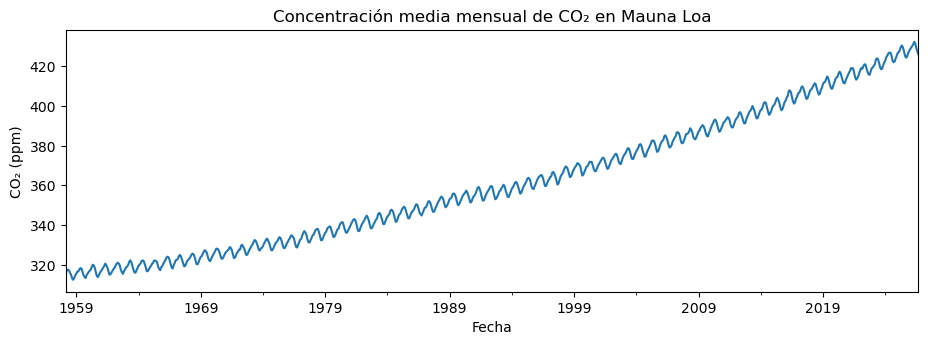

In [4]:
# Construir el índice de fechas.
raw.index = pd.to_datetime(
    raw[["year", "month"]].assign(day=1)
)

# Establecer una frecuencia mensual al inicio de cada mes.
raw = raw.asfreq("MS")

# Seleccionar la concentración media mensual de CO₂.
co2 = raw["average"]

# Graficar la serie temporal.
co2.plot(title="Concentración media mensual de CO₂ en Mauna Loa")
plt.xlabel("Fecha")
plt.ylabel("CO₂ (ppm)")
plt.show()

## 4. Separación de los datos de entrenamiento y prueba

Dividimos la serie cronológicamente:

- **Entrenamiento:** enero de 1975 a diciembre de 2025.
- **Prueba:** enero a septiembre de 2026.

El conjunto de entrenamiento se utilizará para ajustar el modelo.
Reservamos el conjunto de prueba para evaluar posteriormente sus
predicciones con observaciones que no participaron en el ajuste.

La ventana completa comprende 612 meses de entrenamiento y 9 de prueba,
si todas esas fechas están disponibles en el archivo.

También revisamos los registros con `sdev < 0`. En estos registros,
el valor negativo es un indicador de información no disponible,
no una desviación estándar válida.

La referencia de clase identifica dos meses interpolados por NOAA:
diciembre de 1975 y abril de 1984. Conservamos sus valores de `average`
y dejamos documentada su presencia; aquí no realizamos una nueva interpolación.

In [5]:
# Separar la serie respetando el orden temporal.
train = co2.loc["1975-01":"2025-12"].copy()
test = co2.loc["2026-01":"2026-09"].copy()

print(
    f"{len(train)} meses de entrenamiento, "
    f"{len(test)} meses de prueba"
)

# Revisar meses con desviación estándar marcada como no disponible.
raw.loc["1975":"2025"].query("sdev < 0")[
    ["average", "ndays", "sdev"]
]

612 meses de entrenamiento, 9 meses de prueba


,average,ndays,sdev
1975-12-01,330.77,-1,-9.99
1984-04-01,347.37,2,-9.99


## 5. Exploración de la serie: ¿es necesario aplicar logaritmos?

Primero graficamos el conjunto de entrenamiento para observar su tendencia
y sus fluctuaciones estacionales.

Una transformación logarítmica puede ser útil cuando la amplitud de las
fluctuaciones aumenta proporcionalmente al nivel de la serie.
Para explorar esta relación, utilizamos las columnas `average` y
`deseasonalized` del archivo.

Calculamos el componente estacional como:

$$
S_t = \text{average}_t - \text{deseasonalized}_t
$$

Después obtenemos, para cada año:

- **Nivel:** promedio anual de la concentración de CO₂.
- **Amplitud estacional:** diferencia entre el máximo y el mínimo
  del componente estacional durante ese año.

En la segunda gráfica comparamos la amplitud observada con una referencia:
la amplitud que tendríamos si creciera proporcionalmente al nivel,
tomando 1975 como año base.

Si la amplitud observada permanece relativamente estable mientras el
nivel aumenta, esto favorece trabajar con la serie en su escala original.
Si aumenta proporcionalmente al nivel, tendría sentido considerar logaritmos.

Esta comparación utiliza únicamente el periodo de entrenamiento.

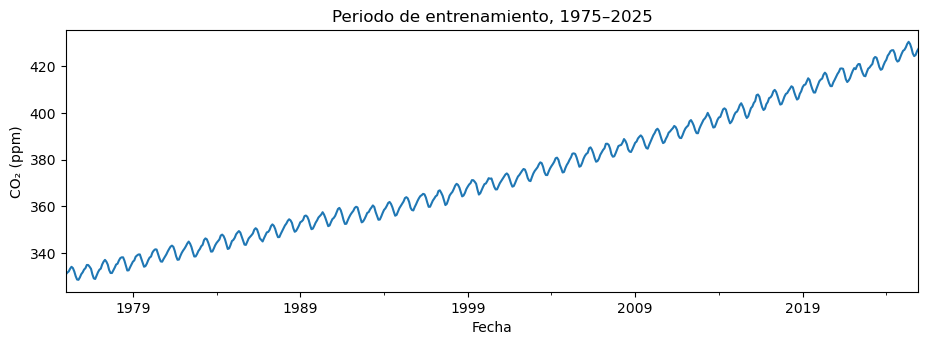

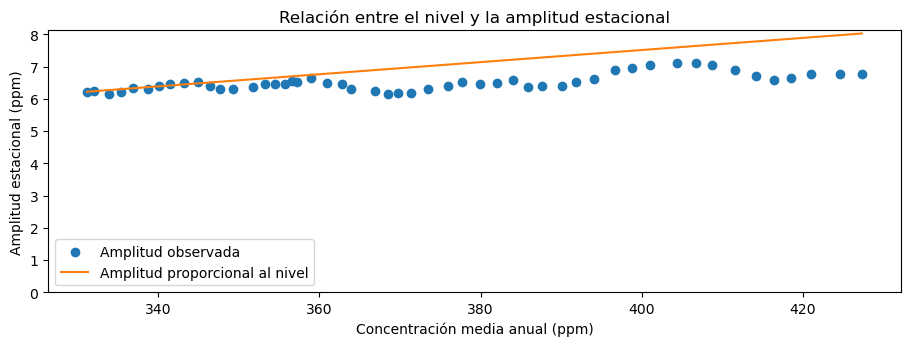

Nivel: 331 → 427 ppm (+29%)
Amplitud: 6.22 → 6.77 ppm (+9%)


In [6]:
# Visualizar la serie de entrenamiento.
train.plot(title="Periodo de entrenamiento, 1975–2025")
plt.xlabel("Fecha")
plt.ylabel("CO₂ (ppm)")
plt.show()

# Componente estacional calculado con las columnas de NOAA.
seasonal = (
    raw["average"] - raw["deseasonalized"]
).loc["1975":"2025"]

# Amplitud estacional anual: máximo menos mínimo.
seasonal_by_year = seasonal.groupby(seasonal.index.year)
swing = seasonal_by_year.max() - seasonal_by_year.min()

# Nivel medio anual de la serie.
level = train.groupby(train.index.year).mean()

# Referencia: amplitud proporcional al nivel, con base en 1975.
proportional_swing = (
    swing.loc[1975] * level / level.loc[1975]
)

# Comparar la amplitud observada con la referencia proporcional.
plt.scatter(
    level,
    swing,
    label="Amplitud observada"
)

plt.plot(
    level,
    proportional_swing,
    color="C1",
    label="Amplitud proporcional al nivel"
)

plt.ylim(0, None)
plt.xlabel("Concentración media anual (ppm)")
plt.ylabel("Amplitud estacional (ppm)")
plt.title("Relación entre el nivel y la amplitud estacional")
plt.legend()
plt.show()

# Comparar los valores del primer y último año.
print(
    f"Nivel: {level.loc[1975]:.0f} → "
    f"{level.loc[2025]:.0f} ppm "
    f"({level.loc[2025] / level.loc[1975] - 1:+.0%})"
)

print(
    f"Amplitud: {swing.loc[1975]:.2f} → "
    f"{swing.loc[2025]:.2f} ppm "
    f"({swing.loc[2025] / swing.loc[1975] - 1:+.0%})"
)

### Decisión: conservar la escala original

En los resultados de clase, el nivel medio de CO₂ aumenta aproximadamente
29%, mientras que la amplitud estacional crece alrededor de 9%.

Si la estacionalidad fuera multiplicativa, esperaríamos que la amplitud
creciera proporcionalmente al nivel de la serie.

Aunque la amplitud aumenta ligeramente, su comportamiento es más cercano
a una estacionalidad aditiva. Por ello, continuamos en la escala original,
sin aplicar logaritmos.

## 6. Primera diferenciación y evaluación de estacionariedad

Aplicamos la prueba de Dickey-Fuller aumentada (ADF) a la serie de
entrenamiento original, incluyendo una constante y una tendencia lineal
mediante `regression="ct"`.

Las hipótesis de la prueba son:

- **H₀:** la serie tiene una raíz unitaria.
- **H₁:** la serie es estacionaria alrededor de una tendencia determinista.

Con un nivel de significancia de 5%, un valor p menor que 0.05 permite
rechazar H₀. Un valor mayor no proporciona evidencia suficiente para rechazarla.

Después calculamos la primera diferencia:

$$
\Delta y_t = y_t - y_{t-1}
$$

Esta transformación representa el cambio de CO₂ entre un mes y el anterior.
Usamos `dropna()` para eliminar el valor faltante inicial generado por
la diferenciación.

Graficamos la función de autocorrelación (ACF) de la serie diferenciada
hasta el rezago 48. Revisamos especialmente los rezagos 12, 24, 36 y 48
porque corresponden a intervalos de uno, dos, tres y cuatro años.

La persistencia de autocorrelaciones importantes en esos rezagos puede
indicar que todavía existe una estructura estacional anual.

ADF, serie original (constante + tendencia): p = 0.995


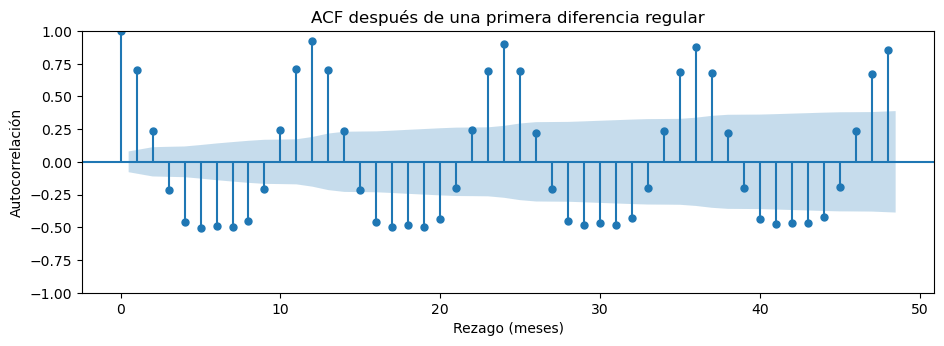

ACF en los rezagos 12, 24, 36 y 48: [0.92 0.9  0.88 0.86]


In [7]:
# Importación adicional necesaria para calcular valores de la ACF.
from statsmodels.tsa.stattools import acf

# Prueba ADF sobre la serie original, con constante y tendencia.
adf_raw = adfuller(train.dropna(), regression="ct")

print(
    "ADF, serie original (constante + tendencia): p =",
    round(adf_raw[1], 3)
)

# Calcular la primera diferencia regular.
diff1 = train.diff().dropna()

# Graficar la autocorrelación después de diferenciar.
plot_acf(
    diff1,
    lags=48,
    title="ACF después de una primera diferencia regular"
)
plt.xlabel("Rezago (meses)")
plt.ylabel("Autocorrelación")
plt.show()

# Consultar la autocorrelación en múltiplos de 12 meses.
acf_values = acf(diff1, nlags=48)
seasonal_lags = [12, 24, 36, 48]

print(
    "ACF en los rezagos 12, 24, 36 y 48:",
    acf_values[seasonal_lags].round(2)
)

### Interpretación de la prueba ADF

En la referencia de clase, la prueba ADF sobre la serie original produce
un valor p aproximado de 0.995.

Como este valor supera 0.05, no rechazamos la hipótesis de raíz unitaria.
Por tanto, la prueba no respalda que la serie original sea estacionaria
alrededor de una tendencia lineal.

Este resultado corresponde a la serie original. La ACF que graficamos
después corresponde a la primera diferencia y permite explorar
la dependencia temporal que permanece tras esa transformación.

## 7. Diferenciación regular y estacional

En los resultados de clase, después de aplicar una primera diferencia
regular, la ACF mantiene autocorrelaciones altas en los rezagos
12, 24, 36 y 48, que disminuyen lentamente, aproximadamente de 0.92 a 0.86.

Esto indica que la dependencia estacional anual persiste.
Por ello, consideramos una diferencia regular y una diferencia
estacional de periodo 12:

- **d = 1:** una diferencia entre meses consecutivos.
- **D = 1:** una diferencia estacional de 12 meses.
- **s = 12:** número de meses del ciclo anual.

La serie transformada se define como:

$$
z_t = (1-B)(1-B^{12})y_t
$$

Aquí, el operador de rezago cumple $By_t = y_{t-1}$.
Al desarrollar la expresión:

$$
z_t = (y_t-y_{t-1})-(y_{t-12}-y_{t-13})
$$

Así, comparamos el cambio mensual actual con el cambio mensual
ocurrido un año antes.

En el código, `diff()` calcula la diferencia regular y `diff(12)`
aplica la diferencia estacional sobre ese resultado.
Después, `dropna()` elimina los valores iniciales sin información suficiente.

Finalmente, aplicamos la prueba ADF a `z`, con constante y sin tendencia
lineal, y graficamos la serie transformada para explorar su comportamiento.

ADF, serie transformada z: p = 1.9e-17


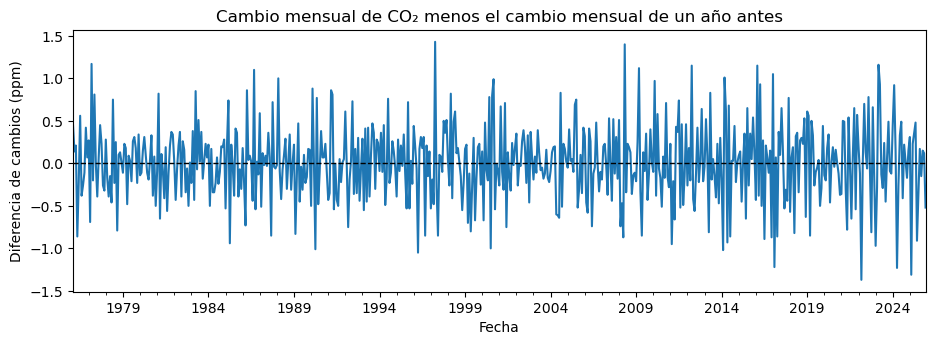

In [8]:
# Aplicar una diferencia regular y una estacional de 12 meses.
z = train.diff().diff(12).dropna()

# Prueba ADF con constante, sin tendencia lineal.
adf_z = adfuller(z, regression="c")

print(f"ADF, serie transformada z: p = {adf_z[1]:.1e}")

# Visualizar la serie transformada.
z.plot(
    title="Cambio mensual de CO₂ menos el cambio mensual de un año antes"
)
plt.xlabel("Fecha")
plt.ylabel("Diferencia de cambios (ppm)")
plt.axhline(0, color="black", linestyle="--", linewidth=1)
plt.show()

### Interpretación del resultado

En la referencia de clase, el valor p de la prueba ADF para la serie
transformada es aproximadamente:

$$
p = 1.9 \times 10^{-17}
$$

Como es menor que 0.05, rechazamos la hipótesis nula de raíz unitaria.
Este resultado respalda trabajar con la transformación que combina
una diferencia regular y una estacional: **d = 1, D = 1 y s = 12**.

Rechazar la presencia de una raíz unitaria no significa que la serie
sea ruido blanco: todavía puede existir autocorrelación que deba
representarse mediante los componentes del modelo.

## 8. Identificación de los órdenes mediante ACF y PACF

Analizamos la serie transformada `z`, que ya tiene una diferencia regular
y una diferencia estacional de 12 meses.

Utilizamos dos gráficas:

- **ACF:** mide la correlación de la serie con sus valores rezagados.
- **PACF:** mide la correlación con un rezago después de controlar
  el efecto de los rezagos intermedios.

Como orientación para proponer modelos:

| Componente | Patrón teórico |
|---|---|
| AR(p) | La PACF se corta después del rezago p y la ACF decae gradualmente. |
| MA(q) | La ACF se corta después del rezago q y la PACF decae gradualmente. |

En una muestra, estos patrones son aproximados. Las barras que sobresalen
de las bandas ayudan a identificar correlaciones relevantes, pero no
determinan por sí solas el modelo final.

Revisamos dos escalas:

- **Mensual:** rezagos 1, 2, 3, etc., para proponer p y q.
- **Estacional:** rezagos 12, 24 y 36, para proponer P y Q.

También consultamos los rezagos cercanos a 12, como 11 y 13,
porque pueden reflejar interacciones entre componentes regulares
y estacionales.

Los órdenes de diferenciación considerados son d = 1 y D = 1,
con periodo s = 12. Los demás órdenes se propondrán a partir de estas
gráficas y se evaluarán mediante el ajuste y el diagnóstico del modelo.

**Nota:** una prueba ADF significativa también puede aparecer si se ha
diferenciado demasiado. Por ello, su resultado respalda la transformación,
pero no demuestra que el número de diferencias sea el adecuado.

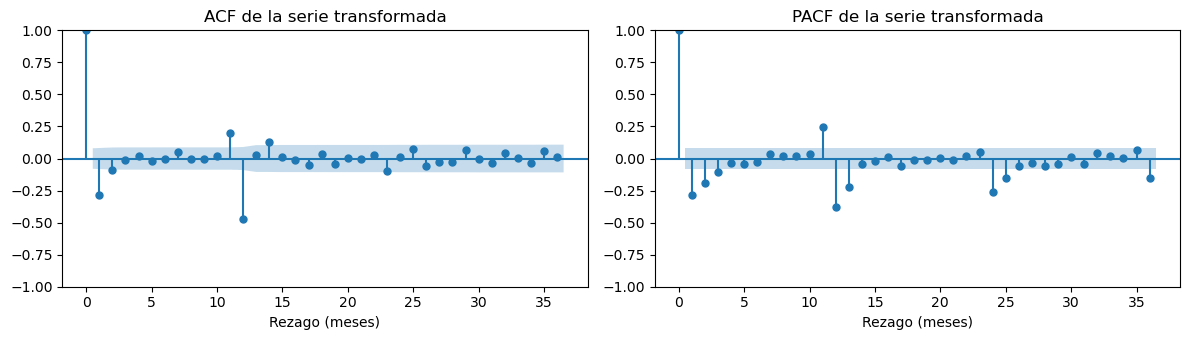

Rezago
1    -0.28
2    -0.09
3    -0.01
11    0.20
12   -0.47
13    0.03
14    0.13
24    0.01
36    0.01
Name: Autocorrelación, dtype: float64

In [9]:
# Graficar la ACF y la PACF de la serie transformada.
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))

plot_acf(
    z,
    lags=36,
    ax=ax[0],
    title="ACF de la serie transformada"
)

plot_pacf(
    z,
    lags=36,
    ax=ax[1],
    method="ywm",
    title="PACF de la serie transformada"
)

for axis in ax:
    axis.set_xlabel("Rezago (meses)")

plt.tight_layout()
plt.show()

# Consultar autocorrelaciones en rezagos seleccionados.
acf_z = acf(z, nlags=36)
lags = [1, 2, 3, 11, 12, 13, 14, 24, 36]

pd.Series(
    acf_z[lags],
    index=pd.Index(lags, name="Rezago"),
    name="Autocorrelación"
).round(2)

## 9. Ajuste del modelo SARIMA

Ajustamos un modelo:

$$
\text{SARIMA}(0,1,1)(0,1,1)_{12}
$$

Sus componentes son:

- **p = 0:** sin término autorregresivo regular.
- **d = 1:** una diferencia regular.
- **q = 1:** un término de media móvil regular.
- **P = 0:** sin término autorregresivo estacional.
- **D = 1:** una diferencia estacional.
- **Q = 1:** un término de media móvil estacional.
- **s = 12:** periodo estacional anual.

Entregamos al modelo la serie original de entrenamiento (`train`),
porque SARIMAX incorpora las diferencias indicadas en sus parámetros.
Usar `z` con estos mismos órdenes aplicaría las diferencias nuevamente.

Sobre la serie diferenciada, el modelo puede escribirse como:

$$
z_t = (1+\theta B)(1+\Theta B^{12})\varepsilon_t
$$

Al desarrollar:

$$
z_t = \varepsilon_t
+ \theta\varepsilon_{t-1}
+ \Theta\varepsilon_{t-12}
+ \theta\Theta\varepsilon_{t-13}
$$

Aquí, $\theta$ y $\Theta$ son los coeficientes de media móvil
regular y estacional, respectivamente.

Para este modelo, la ACF teórica puede ser distinta de cero
en los rezagos positivos 1, 11, 12 y 13.
En particular, los rezagos 11 y 13 comparten la misma autocorrelación:

$$
\rho_{11} = \rho_{13}
= \frac{\theta\Theta}{(1+\theta^2)(1+\Theta^2)}
$$

Comparamos este valor teórico con las autocorrelaciones observadas
para evaluar qué tan bien representa el modelo esos rezagos.

In [10]:
# Ajustar el modelo sobre la serie original de entrenamiento.
fit = sm.tsa.SARIMAX(
    train,
    order=(0, 1, 1),
    seasonal_order=(0, 1, 1, 12),
    trend="n"
).fit(disp=False)

# Mostrar coeficientes, errores estándar e intervalos de confianza.
print(fit.summary().tables[1])

# Extraer los coeficientes de media móvil.
theta = fit.params["ma.L1"]
Theta = fit.params["ma.S.L12"]

# Autocorrelación teórica en los rezagos 11 y 13.
rho_theoretical = (
    theta * Theta
    / ((1 + theta**2) * (1 + Theta**2))
)

# Autocorrelaciones observadas de la serie diferenciada.
acf_z = acf(z, nlags=36)

print(
    "\nACF que predice el modelo en los rezagos 11 y 13:",
    round(rho_theoretical, 2)
)

print(
    "ACF observada en los rezagos 11 y 13:",
    round(acf_z[11], 2),
    round(acf_z[13], 2)
)

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.4104      0.035    -11.757      0.000      -0.479      -0.342
ma.S.L12      -0.8848      0.022    -39.709      0.000      -0.928      -0.841
sigma2         0.0991      0.005     19.560      0.000       0.089       0.109

ACF que predice el modelo en los rezagos 11 y 13: 0.17
ACF observada en los rezagos 11 y 13: 0.2 0.03


## 10. Comparación de modelos: AIC, BIC y Ljung-Box

Ajustamos los cinco modelos candidatos y comparamos:

- **AIC y BIC:** evalúan el ajuste penalizando la complejidad.
  En ambos criterios, un valor menor es preferible.
- **Ljung-Box:** evalúa conjuntamente si las autocorrelaciones
  de los residuos hasta el rezago 24 son cero.

Las hipótesis de Ljung-Box son:

- **H₀:** las autocorrelaciones de los residuos hasta el rezago 24 son cero.
- **H₁:** al menos una de esas autocorrelaciones es distinta de cero.

Si el valor p es mayor que 0.05, no rechazamos H₀: no encontramos
evidencia suficiente de autocorrelación residual hasta ese rezago.
Esto no demuestra independencia ni normalidad de los residuos.

Excluimos los primeros 13 residuos para reducir el efecto de la
inicialización del modelo, siguiendo el procedimiento de clase.

Además, ajustamos los grados de libertad mediante `model_df=k`,
donde k es el número de coeficientes AR y MA, regulares y estacionales.
Como estos modelos no incluyen tendencia ni variables explicativas,
calculamos k como el total de parámetros menos la varianza `sigma2`.

Finalmente, ordenamos los resultados por BIC para comparar el ajuste
con una penalización por complejidad.

In [11]:
candidates = {
    "airline (0,1,1)(0,1,1)": (
        (0, 1, 1), (0, 1, 1, 12)
    ),
    "+ AR(1)": (
        (1, 1, 1), (0, 1, 1, 12)
    ),
    "+ MA(2), q = 2": (
        (0, 1, 2), (0, 1, 1, 12)
    ),
    "+ seasonal AR(1)": (
        (0, 1, 1), (1, 1, 1, 12)
    ),
    "AR version (1,1,0)(1,1,0)": (
        (1, 1, 0), (1, 1, 0, 12)
    ),
}

rows = []
candidate_fits = {}

for name, (order, seasonal_order) in candidates.items():
    # Ajustar el modelo con los datos de entrenamiento.
    f = sm.tsa.SARIMAX(
        train,
        order=order,
        seasonal_order=seasonal_order,
        trend="n"
    ).fit(disp=False)

    candidate_fits[name] = f

    # Número de coeficientes AR y MA, excluyendo sigma2.
    k = len(f.params) - 1

    # Excluir los primeros 13 residuos.
    residuals = f.resid.iloc[13:].dropna()

    # Prueba de Ljung-Box hasta el rezago 24.
    lb_p = acorr_ljungbox(
        residuals,
        lags=[24],
        model_df=k,
        return_df=True
    )["lb_pvalue"].iloc[0]

    rows.append({
        "model": name,
        "AIC": f.aic,
        "BIC": f.bic,
        "Ljung-Box p": lb_p,
    })

# Ordenar por BIC antes de redondear los resultados.
comparison = (
    pd.DataFrame(rows)
    .sort_values("BIC")
    .reset_index(drop=True)
)

comparison.round({
    "AIC": 1,
    "BIC": 1,
    "Ljung-Box p": 3
})

,model,AIC,BIC,Ljung-Box p
0,"airline (0,1,1)(0,1,1)",339.6,352.8,0.764
1,"+ MA(2), q = 2",338.1,355.7,0.870
2,+ AR(1),338.1,355.7,0.869
3,+ seasonal AR(1),341.4,358.9,0.697
4,"AR version (1,1,0)(1,1,0)",516.8,529.9,0.000
